# L17 — Did Tim Paint a Vermeer? A Camera Model of a Room — Companion Notebook
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L17-CameraModels/L17_Vermeer.ipynb)

In the documentary *Tim's Vermeer* (2013), engineer Tim Jenison spends months copying Vermeer's *The Music Lesson*
with a lens and a small mirror, to test the idea that Vermeer painted with optical help. In 2020 David Stork,
Christopher Tyler and Sara Schechner looked hard at the evidence in **"Did Tim Paint a Vermeer?"** (*Journal of
Imaging Science and Technology* 64(6), 060403) and concluded that it is "extraordinarily unlikely" Vermeer used
Jenison's device.

Their arguments are camera-model arguments. This notebook builds a plain room with a tiled floor (not any real
painting) and looks at it through the camera model of Lecture 17, so you can check each argument yourself. The
checkerboard calibration itself is in `L17_Camera_Models.ipynb`.

| Section | Question from the paper | Tool from L17 |
|---------|-------------------------|---------------|
| 1 | What does a camera see of a room? | K, R, t |
| 2 | Is correct perspective proof of a lens? | vanishing points |
| 3 | How big is the picture on the back wall? | similar triangles |
| 4 | How much could Jenison's device see at once? | field of view |
| 5 | Can we get a floor plan from a picture? | homography |
| 6 | Why use a lens at all? Disk-shaped highlights | aperture, focus |
| 7 | A bowed line on the virginals: the lens? | radial distortion |

In [2]:
import numpy as np, cv2
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = "#C8962C", "#B82828", "#1A7A8A", "#2E7D50", "#1A3A5C", "#7B4EA0", "#7A8FA6"
np.set_printoptions(suppress=True, precision=3)

## 1 · A camera in a room: K, R and t

Room axes: $x$ along the back wall (right), $y$ into the room, $z$ **up** (right-handed, like a map with height).
The floor is $z = 0$, tiled in 0.5 m squares; the back wall is at $y = 7$ m; a window on the left wall lights the
room.

The painter's eye (the camera centre) is at $C = (0, 0, 1.2)$, sitting, looking straight at the back wall. The
camera's axes are $x$ right, $y$ **down**, $z$ forward. Each row of $R$ says where one camera axis points in the
room: camera $x$ = room $x$ → $(1, 0, 0)$; camera $y$ (down) = room $-z$ → $(0, 0, -1)$; camera $z$ (forward) =
room $y$ → $(0, 1, 0)$. That is a real rotation (a 90° tip about $x$; determinant $+1$), and
$t = -R\,C = (0, 1.2, 0)$. K has $f = 600$ px and centre $(320, 240)$ for a 640 × 480 picture.

**By hand:** the floor point $(1, 4, 0)$ → camera $(1, 1.2, 4)$ → pixel
$(600 \times 1/4 + 320,\ 600 \times 1.2/4 + 240) = (470, 420)$.

In [3]:
K = np.array([[600., 0, 320], [0, 600., 240], [0, 0, 1]])
R = np.array([[1., 0, 0], [0, 0, -1], [0, 1, 0]]); C = np.array([0, 0, 1.2]); t = -R @ C
print('det R =', round(np.linalg.det(R), 3), '| t =', t)
W, H = 640, 480

def to_pixel(Xw):
    Xc = (R @ np.asarray(Xw, float).T).T + t
    h = (K @ Xc.T).T
    return h[:, :2] / h[:, 2:]

for P in [(1, 4, 0), (-1, 6, 0)]:
    print(f"floor point {P} -> camera {R @ np.array(P, float) + t} -> pixel {to_pixel([P])[0]}")

det R = 1.0 | t = [0.  1.2 0. ]
floor point (1, 4, 0) -> camera [1.  1.2 4. ] -> pixel [470. 420.]
floor point (-1, 6, 0) -> camera [-1.   1.2  6. ] -> pixel [220. 360.]


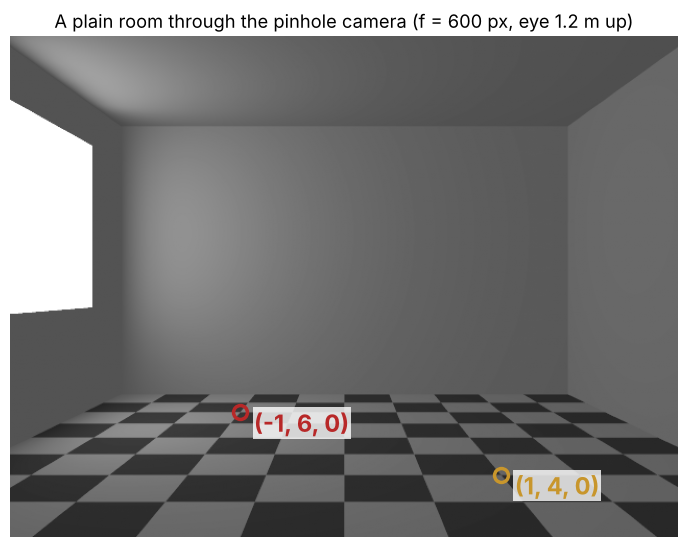

In [4]:
ROOM = dict(x0=-2.5, x1=2.5, ceil=3.0, back=7.0)
WIN = dict(y0=4.6, y1=6.2, z0=1.0, z1=2.6)          # window in the left wall (x = -2.5), near the back: y along, z up
STUDS = np.array([[x, 6.99, 1.5] for x in (-1.6, -0.8, 0.0, 0.8, 1.6)])   # small brass studs on the back wall

def cast(K, R, C, size=(W, H), ss=3, k1=0.0):
    # Render the room through the pinhole camera (optionally a barrel lens k1): returns image, depth, plane id
    w, h = size
    us, vs = np.meshgrid((np.arange(w * ss) + 0.5) / ss - 0.5, (np.arange(h * ss) + 0.5) / ss - 0.5)
    x = (us - K[0, 2]) / K[0, 0]; y = (vs - K[1, 2]) / K[1, 1]
    if k1:                                                  # pixel shows the ray of its *undistorted* position
        xu, yu = x.copy(), y.copy()
        for _ in range(20):
            r2 = xu ** 2 + yu ** 2; xu, yu = x / (1 + k1 * r2), y / (1 + k1 * r2)
        x, y = xu, yu
    d = np.stack([x, y, np.ones_like(x)], -1) @ R            # camera ray -> world direction (R^T d)
    tbest = np.full(x.shape, np.inf); plane = np.zeros(x.shape, int)
    for pid, (axis, val) in enumerate([(2, 0.0), (2, ROOM["ceil"]), (1, ROOM["back"]), (0, ROOM["x0"]), (0, ROOM["x1"])], 1):
        with np.errstate(divide="ignore", invalid="ignore"):
            tt = (val - C[axis]) / d[..., axis]
        ok = (tt > 0) & (tt < tbest)
        tbest[ok] = tt[ok]; plane[ok] = pid
    P = C + d * tbest[..., None]
    # Light from the window: an area light (5 x 5 sample points), cos x cos / d^2, plus a little ambient light
    normals = {1: (0, 0, 1), 2: (0, 0, -1), 3: (0, -1, 0), 4: (1, 0, 0), 5: (-1, 0, 0)}
    N = np.zeros(P.shape)
    for pid, n in normals.items(): N[plane == pid] = n
    irr = np.full(x.shape, 0.12)
    for wy in np.linspace(WIN["y0"], WIN["y1"], 5):
        for wz in np.linspace(WIN["z0"], WIN["z1"], 5):
            with np.errstate(invalid="ignore"):
                L = np.array([ROOM["x0"], wy, wz]) - P; dist = np.linalg.norm(L, axis=-1); L /= dist[..., None]
            cos_s = np.clip((N * L).sum(-1), 0, None); cos_w = np.clip(-L[..., 0], 0, None)    # window faces +x
            irr += (2.2 / 25) * cos_s * cos_w / np.maximum(dist, 0.3) ** 2
    alb = np.where(plane == 1, np.where((np.floor(P[..., 0] / 0.5) + np.floor(P[..., 1] / 0.5)) % 2 == 0, 0.80, 0.12), 0.70)
    alb = np.where(plane == 2, 0.55, alb)
    img = alb * irr
    win = (plane == 4) & (P[..., 1] > WIN["y0"]) & (P[..., 1] < WIN["y1"]) & (P[..., 2] > WIN["z0"]) & (P[..., 2] < WIN["z1"])
    img[win] = 1.6
    img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    depth = cv2.resize(tbest * d[..., 1], size, interpolation=cv2.INTER_NEAREST)    # distance along the view (room y)
    plane = cv2.resize(plane.astype(np.float32), size, interpolation=cv2.INTER_NEAREST).astype(int)
    return img, depth, plane

img, depth, plane = cast(K, R, C)
studs_px = to_pixel(STUDS)
def show(im): return np.clip(im, 0, 1) ** (1 / 2.2)                 # display gamma

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.imshow(show(img), cmap="gray", vmin=0, vmax=1)
for P, col in [((1, 4, 0), GOLD), ((-1, 6, 0), RED)]:
    u, v = to_pixel([P])[0]; ax.plot(u, v, "o", ms=10, mfc="none", mec=col, mew=2.5)
    ax.annotate(str(P), (u, v), xytext=(10, -14), textcoords="offset points", color=col, fontsize=17, weight="bold",
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
ax.set_title("A plain room through the pinhole camera (f = 600 px, eye 1.2 m up)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 2 · Is correct perspective proof of a lens? Vanishing points

Parallel lines in the room meet in the picture at a **vanishing point**. A direction $d$ (a point "at infinity")
goes through the camera like any point, but without $t$: its vanishing point is $K R\,d$, divided by the last
number.

* Lines running straight into the room, room direction $d = (0, 1, 0)$: $R\,d = (0, 0, 1)$ (straight ahead for
  the camera) and $K(0, 0, 1) = (c_x, c_y, 1)$. They meet at the **centre of the picture**, $(320, 240)$.
* The tiles' diagonals, $d = (1, 1, 0)$: $R\,d = (1, 0, 1)$ and $K(1, 0, 1) = (600 + 320, 240, 1)$ → $(920, 240)$:
  $f$ pixels to the right of the centre. Painters call it the **distance point**: its distance from the centre is the viewing
  distance, which is $f$.

So a tiled floor tells you $c_x, c_y$ and $f$. And anyone can draw it: a pin at the vanishing point and a chalked
string give exactly these lines. Stork, Tyler and Schechner point out that the pinholes found at the vanishing
points of some Vermeer paintings fit that kind of string construction. **Correct perspective is the geometry of
K, however it was made; it does not prove a lens.**

direction (0, 1, 0): K R d = [320. 240.   1.] -> vanishing point [320. 240.]
direction (1, 1, 0): K R d = [920. 240.   1.] -> vanishing point [920. 240.]
direction (-1, 1, 0): K R d = [-280.  240.    1.] -> vanishing point [-280.  240.]


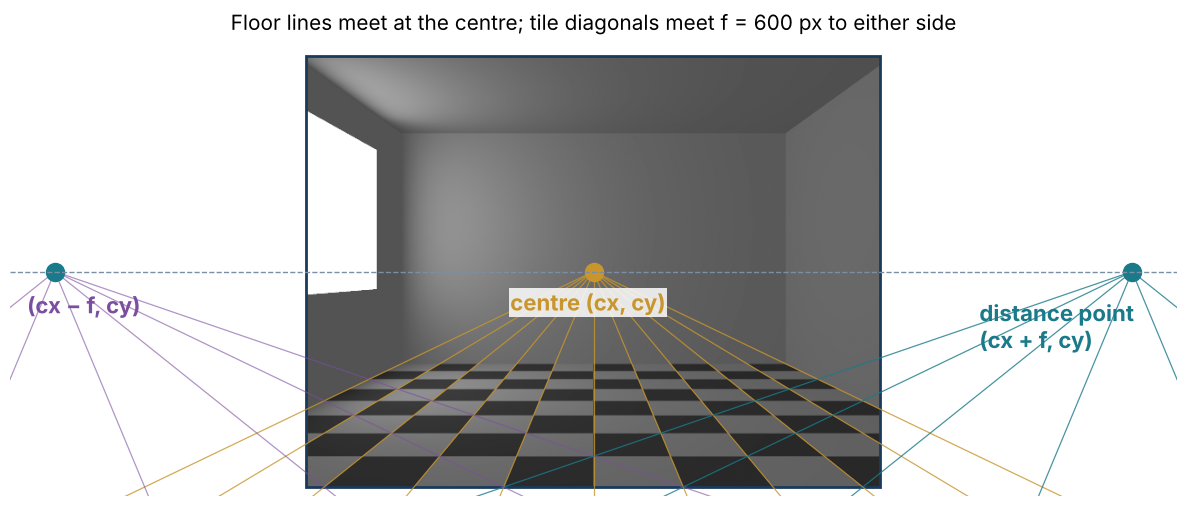

In [5]:
for d in [(0, 1, 0), (1, 1, 0), (-1, 1, 0)]:
    h = K @ (R @ np.array(d, float)); print(f"direction {d}: K R d = {h} -> vanishing point {h[:2] / h[2]}")

# Check on the render: extend the tile edges and diagonals and see where they meet
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.imshow(show(img), cmap="gray", vmin=0, vmax=1, extent=(-0.5, W - 0.5, H - 0.5, -0.5))
for x in np.arange(-2.5, 2.51, 0.5):                       # tile edges running into the room
    p = to_pixel([(x, 1.0, 0), (x, 7.0, 0)]); vp = np.array([320, 240])
    ax.plot([p[0, 0], vp[0]], [p[0, 1], vp[1]], color=GOLD, lw=0.9, alpha=0.8)
for x0 in np.arange(-2.5, 2.6, 1.0):                       # tile diagonals
    p = to_pixel([(x0, 1.0, 0)]); ax.plot([p[0, 0], 920], [p[0, 1], 240], color=TEAL, lw=0.9, alpha=0.8)
    ax.plot([p[0, 0], -280], [p[0, 1], 240], color=PURPLE, lw=0.9, alpha=0.6)
ax.plot(320, 240, "o", color=GOLD, ms=13); ax.annotate("centre (cx, cy)", (320, 240), xytext=(-60, -28), textcoords="offset points", color=GOLD, weight="bold", fontsize=16, bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.plot([920, -280], [240, 240], "o", color=TEAL, ms=13)
ax.annotate("distance point\n(cx + f, cy)", (920, 240), xytext=(-110, -55), textcoords="offset points", color=TEAL, weight="bold", fontsize=16)
ax.annotate("(cx − f, cy)", (-280, 240), xytext=(-20, -30), textcoords="offset points", color=PURPLE, weight="bold", fontsize=16)
ax.axhline(240, color=GREY, lw=1, ls="--")
ax.add_patch(plt.Rectangle((-0.5, -0.5), W, H, fill=False, ec=NAVY, lw=2))
ax.set_xlim(-330, 970); ax.set_ylim(H + 10, -20); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Floor lines meet at the centre; tile diagonals meet f = 600 px to either side", fontsize=15)
plt.tight_layout(); plt.show()

## 3 · How big is the picture on the back wall? Similar triangles

Philip Steadman (*Vermeer's Camera*, 2001) reconstructed the painter's viewpoint in several interiors from the
floor tiles and from objects whose real sizes are known (maps, chairs, the virginals, which survive). Then he
carried the edges of each picture's "pyramid of vision" back through the viewpoint to the back wall of the
studio. For at least six paintings, the rectangle on the wall is the exact size of the canvas. His explanation: a
lens at the viewpoint, a booth at the back, and the wall as the screen. A screen $f$ behind the lens is exactly
the pinhole box of slide 5, and the picture's size is $f \cdot Y / Z$.

**By hand** (example numbers, not Steadman's): a virginals 1.6 m wide, 4 m in front of the lens, with the screen
1.5 m behind the lens: $1.6 \times 1.5 / 4 = 0.6$ m wide on the wall.

In [6]:
def image_size(Y, Z, f): return Y * f / Z
print(f"1.6 m wide, 4 m away, screen 1.5 m behind the lens: {image_size(1.6, 4, 1.5):.2f} m on the wall")
print(f"the same virginals 6 m away: {image_size(1.6, 6, 1.5):.2f} m")

1.6 m wide, 4 m away, screen 1.5 m behind the lens: 0.60 m on the wall
the same virginals 6 m away: 0.40 m


## 4 · How much could Jenison's device see at once? Field of view

The paper describes Jenison's device from his notebooks: a lens with $f = 75$ cm and a 10 cm opening, a concave
mirror, and a small 45° mirror that the painter looks into beside the canvas. Its field of view is only about 4°.

At distance $Z$, a view $\theta$ wide covers $2 Z \tan(\theta/2)$. From 3 m away (an example distance), 4° covers
about 21 cm of the room: a small patch, which fits the independent painter Jonathan Janson's report that he could
paint only a few square inches before the optics had to be realigned. The bowed contour on the virginals (§7)
spans about 7.2°, so it needs at least two separate views.

In [7]:
for theta, Z in [(4, 3.0), (4, 5.0)]:
    print(f"{theta} deg view from {Z} m covers {2 * Z * np.tan(np.radians(theta / 2)) * 100:.0f} cm of the room")
print(f"7.2 deg contour / 4 deg view = {7.2 / 4:.1f} -> at least 2 views")
# a phone's 1x camera for comparison: f = W, about 53 deg
print(f"phone 1x (53 deg) from 3 m covers {2 * 3 * np.tan(np.radians(53.1 / 2)):.1f} m")

4 deg view from 3.0 m covers 21 cm of the room
4 deg view from 5.0 m covers 35 cm of the room
7.2 deg contour / 4 deg view = 1.8 -> at least 2 views
phone 1x (53 deg) from 3 m covers 3.0 m


## 5 · A floor plan from a picture: the floor is a plane

Every floor point has $z = 0$, so the third column of $R$ is multiplied by 0 and drops out: floor → picture is a
homography (L8), $H = K\,[\,r_1\ r_2\ t\,]$ acting on $(x, y, 1)$. Same form as a checkerboard in Zhang's
method, where the board is the plane $z = 0$ too. Run it backwards and the floor comes out as a
plan, with square tiles. That is how Steadman could draw the floor plan of a room he could only see in paintings.
(A twist from the paper: the household inventory of the house where Vermeer painted lists no tiled floor, so the
tiles may be the painter's invention.)

H = K [r1 r2 t] =
 [[600. 320.   0.]
 [  0. 240. 720.]
 [  0.   1.   0.]]
check: floor (1, 4) -> [470. 420.]  (slide: (470, 420))


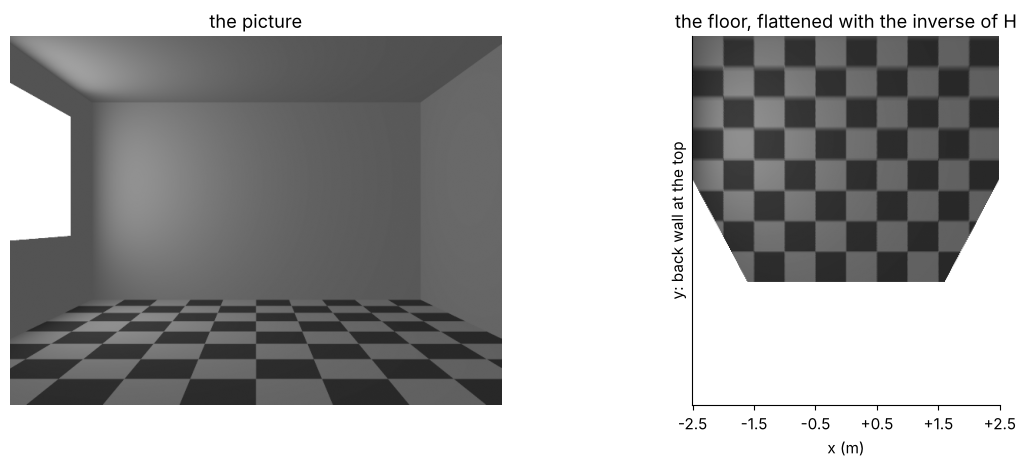

In [8]:
Hf = K @ np.column_stack([R[:, 0], R[:, 1], t])          # floor (x, y, 1) -> pixel
print("H = K [r1 r2 t] =\n", Hf)
print("check: floor (1, 4) ->", (Hf @ [1, 4, 1])[:2] / (Hf @ [1, 4, 1])[2], " (slide: (470, 420))")

S = 60.0                                                  # plan: 60 px per metre, x -2.5..2.5, z 1..7
T_floor_from_plan = np.array([[1 / S, 0, -2.5], [0, -1 / S, 7.0], [0, 0, 1]])
plan = cv2.warpPerspective(show(img).astype(np.float32), np.linalg.inv(Hf @ T_floor_from_plan), (int(5 * S), int(6 * S)),
                           borderValue=1.0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.33, 1]})
ax[0].imshow(show(img), cmap="gray", vmin=0, vmax=1); ax[0].set_title("the picture"); ax[0].axis("off")
ax[1].imshow(plan, cmap="gray", vmin=0, vmax=1); ax[1].set_title("the floor, flattened with the inverse of H")
ax[1].set_xlabel("x (m)"); ax[1].set_ylabel("y: back wall at the top")
ax[1].set_xticks(np.arange(0, 5.01, 1) * S, [f"{v:+.1f}" for v in np.arange(-2.5, 2.6, 1)]); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

## 6 · Why use a lens at all? Light, focus and disk-shaped highlights

A pinhole makes everything sharp but lets in very little light. The light a hole collects grows with its area,
so with the **square** of its diameter: Jenison's 10 cm lens collects $(100 / 1)^2 = 10{,}000$ times the light of a
1 mm pinhole.

The price: a lens is sharp at one distance only. A bright point at another distance spreads into a small
**disk**. For a lens focused at $Z_f$, a point at $Z$ makes a disk about $f\,A\,|1/Z_f - 1/Z|$ pixels across
($A$ = opening in metres, $f$ in pixels).

Some of Vermeer's highlights look exactly like such disks. The paper notes that Jenison's method does not explain
them, though a camera obscura with a lens would. Below: five small brass studs on the back wall (6.99 m away),
seen through a pinhole and through a 10 cm lens focused at 4 m.

10 cm lens vs 1 mm pinhole: 10,000 x the light
10 cm lens vs 2 cm lens: 25 x
blur disk for the back wall (7 m away), lens focused at 4 m: 6.4 px across
blur disk for a floor tile at 4 m: 0.0 px


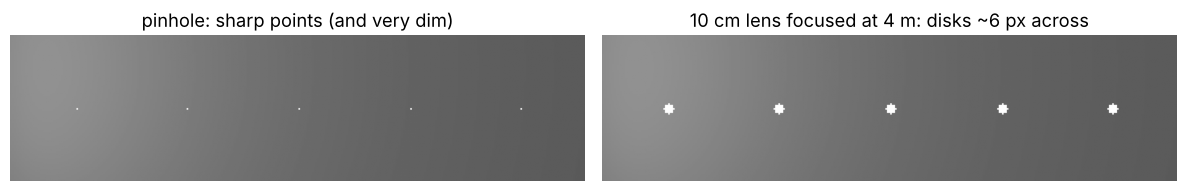

In [9]:
print(f"10 cm lens vs 1 mm pinhole: {(100 / 1) ** 2:,.0f} x the light")
print(f"10 cm lens vs 2 cm lens: {(10 / 2) ** 2:.0f} x")

A, Zf = 0.10, 4.0
blur = lambda Z: K[0, 0] * A * abs(1 / Zf - 1 / Z)
print(f"blur disk for the back wall (7 m away), lens focused at 4 m: {blur(7.0):.1f} px across")
print(f"blur disk for a floor tile at 4 m: {blur(4.0):.1f} px")

# Pinhole image: the room plus 5 tiny bright studs (HDR value 40, one pixel each)
sharp = img.copy()
for u, v in studs_px: sharp[int(round(v)), int(round(u))] = 40.0

def disk(dpx):
    r = max(dpx / 2, 0.5); n = int(np.ceil(r)) * 2 + 1
    yy, xx = np.mgrid[:n, :n] - n // 2; k = (xx ** 2 + yy ** 2 <= r ** 2).astype(np.float32); return k / k.sum()

# Lens image: blur by depth, in depth bands (a simple thin-lens approximation)
lens = np.zeros_like(sharp); edges = np.linspace(depth[np.isfinite(depth)].min(), 7.01, 14)
for a, b in zip(edges[:-1], edges[1:]):
    m = (depth >= a) & (depth < b)
    if m.any(): lens[m] = cv2.filter2D(sharp.astype(np.float32), -1, disk(blur((a + b) / 2)))[m]
lens[~np.isfinite(depth)] = sharp[~np.isfinite(depth)]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
box = (int(studs_px[:, 0].min()) - 40, int(studs_px[:, 0].max()) + 40, int(studs_px[0, 1]) - 45, int(studs_px[0, 1]) + 45)
for a_, im, title in [(ax[0], sharp, "pinhole: sharp points (and very dim)"),
                      (ax[1], lens, f"10 cm lens focused at 4 m: disks ~{blur(7.0):.0f} px across")]:
    a_.imshow(show(im)[box[2]:box[3], box[0]:box[1]], cmap="gray", vmin=0, vmax=1); a_.set_title(title); a_.axis("off")
plt.tight_layout(); plt.show()

**The brightness gradient.** The film argued that the light falling off along the rear wall is something the
eye cannot see, so its presence in the painting means optics. A camera certainly measures it: below, the back wall
in our render, left to right. The paper calls the "cannot be seen" claim patently false and shows similar
gradients in paintings by de Hooch, Hals and Codde, Palamedesz, and even Edward Hopper, none made with optics.
A camera measures what a careful painter can also see.

back wall, row 214: brightest 0.283 (left) / darkest 0.099 (right) = 2.9 x


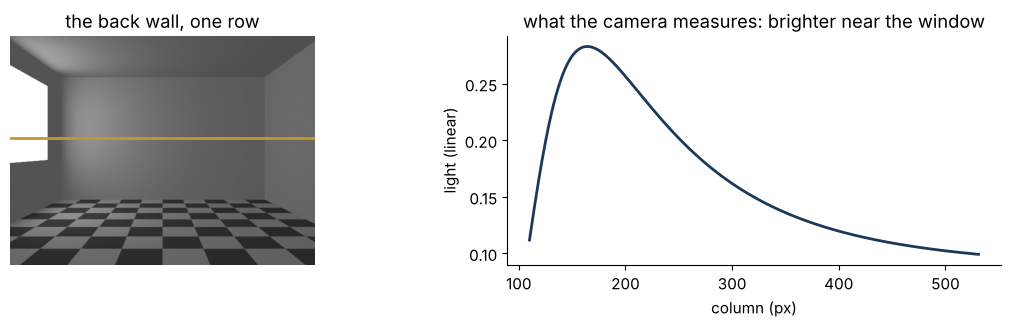

In [10]:
row = int(round(to_pixel([(0, 7.0, 1.5)])[0, 1]))
cols = np.where(plane[row] == 3)[0][3:-3]            # back wall, away from the corners
prof = img[row, cols]
print(f"back wall, row {row}: brightest {prof.max():.3f} (left) / darkest {prof.min():.3f} (right) = {prof.max() / prof.min():.1f} x")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.33, 1]})
ax[0].imshow(show(img), cmap="gray", vmin=0, vmax=1); ax[0].axhline(row, color=GOLD, lw=2); ax[0].axis("off")
ax[0].set_title("the back wall, one row")
ax[1].plot(cols, prof, color=NAVY, lw=2); ax[1].set_xlabel("column (px)"); ax[1].set_ylabel("light (linear)")
ax[1].set_title("what the camera measures: brighter near the window")
plt.tight_layout(); plt.show()

## 7 · A bowed line on the virginals: the lens?

The film points to one contour on the virginals that is very slightly curved, and says Jenison's copy picked up
the same curve from his optics. The paper's answer is a camera-model argument. Radial distortion
(L17 slide 17) moves every point by a factor $1 + k_1 r^2$ that depends only on where it is in the picture, so a
lens that bends one line bends its neighbours too, by about as much. In the painting the nearby contours are
straight. And the contour spans about 7.2°, more than the device's 4° view (§4), so it would have been painted in
pieces and would sag as several arcs, not one smooth bow. Their verdict: a slip of the hand or the string. (The
paper notes that Metsu's *Lady at the virginals* has a similar single bowed contour.)

Below: the room through a barrel lens ($k_1 = -0.35$) next to the true room with one hand-drawn bowed line.

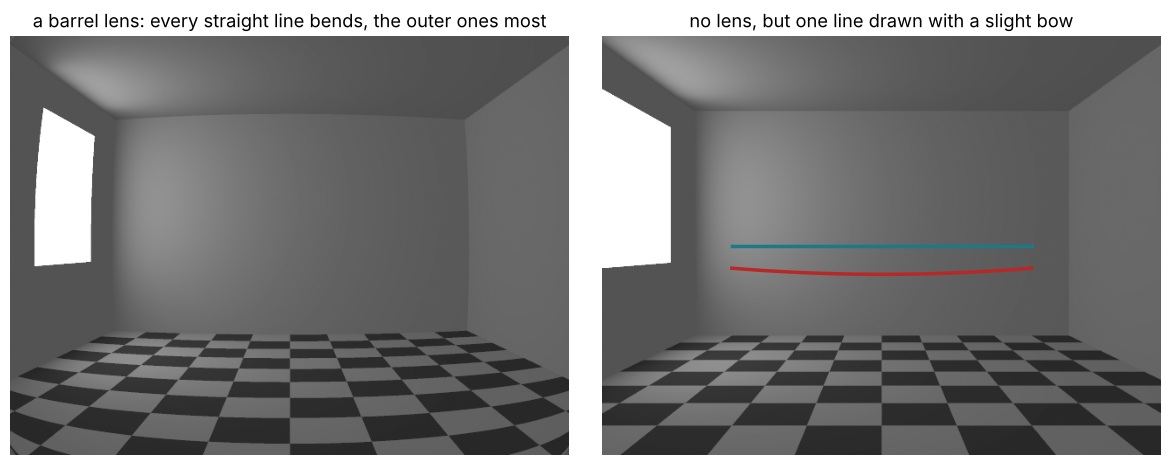

In [11]:
bent, _, _ = cast(K, R, C, k1=-0.35)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].imshow(show(bent), cmap="gray", vmin=0, vmax=1); ax[0].set_title("a barrel lens: every straight line bends, the outer ones most")
ax[1].imshow(show(img), cmap="gray", vmin=0, vmax=1); ax[1].set_title("no lens, but one line drawn with a slight bow")
p0, p1 = to_pixel([(-2.0, 6.99, 0.9), (2.0, 6.99, 0.9)])                       # a straight line on the back wall
for a_, sag in [(ax[1], 7)]:
    s = np.linspace(0, 1, 50); xs = p0[0] + s * (p1[0] - p0[0]); ys = p0[1] + s * (p1[1] - p0[1]) + sag * 4 * s * (1 - s)
    a_.plot(xs, ys, color=RED, lw=2.5)
q0, q1 = to_pixel([(-2.0, 6.99, 1.2), (2.0, 6.99, 1.2)])
ax[1].plot([q0[0], q1[0]], [q0[1], q1[1]], color=TEAL, lw=2.5)
for a_ in ax: a_.axis("off")
plt.tight_layout(); plt.show()

## 8 · Try at home

1. **Move the painter.** Put the eye at $C = (1, 0, 1.2)$ (and keep $R$). Where are the vanishing point and the
   distance points now? Does $f$ change?
2. **Find f from a photo.** Photograph a tiled floor (or a checkerboard on the floor) square-on from eye height.
   Mark where the tile edges meet and where the diagonals meet. Their distance is your phone's $f$ in pixels.
   Compare with your calibration in `L17_Camera_Models.ipynb` §11.
3. **Focus.** In §6, focus the lens at 7 m instead of 4 m. Which parts of the room blur now?
4. **Your verdict.** Which piece of evidence in the paper do you find strongest, and what would *you* measure in a
   Vermeer to settle it?

**Watch / read:** *Tim's Vermeer* (2013, dir. Teller). D. G. Stork, C. W. Tyler, S. J. Schechner, "Did Tim Paint a
Vermeer?", *J. Imaging Sci. Technol.* 64(6), 060403 (2020). P. Steadman, *Vermeer's Camera* (2001).